> **หมายเหตุ:** outputs ที่บันทึกไว้เป็นการรัน single-label รุ่นก่อน ไม่ใช่ผลของโค้ด multi-label ปัจจุบัน; ต้องรัน notebook ใหม่จึงจะได้ checkpoint รุ่นนี้

# RakForest — Train multi-label audio classifier

ฝึก CNN จาก log-Mel spectrogram ให้ทำนายหลายคลาสในเสียงช่วงละ 4 วินาทีได้พร้อมกัน ใช้ `target_labels` จาก manifest ของ 02. ระหว่างฝึกจะสุ่มผสม waveform จาก train split เพื่อสร้างตัวอย่างเสียงซ้อนแบบ on-the-fly; ไม่สร้างไฟล์เสียงผสมถาวร และไม่ผสม validation/test

เลือก checkpoint จาก validation macro-F1 ที่ threshold 0.5. Test split เก็บไว้ประเมินใน 04. Synthetic mixes ช่วยเพิ่มกรณีเสียงซ้อน แต่ยังต้องเก็บ/annotate เสียงจริงที่มีหลายเหตุการณ์เพื่อยืนยันประสิทธิภาพ.

## แนวทางของงาน: ตรวจจับหลายเหตุการณ์ในเสียงเดียว (Multi-label)

### งานนี้อยู่ส่วนไหนของกระบวนการ

ส่วนนี้คือ **การฝึกโมเดล Machine Learning** โดยใช้ข้อมูลที่เตรียมไว้จาก `02_eda_cleaning.ipynb` และส่ง checkpoint ไปประเมินใน `04_evaluate_model.ipynb` ก่อนทดลองเสียงใหม่ใน `05_infer_new_audio.ipynb` ส่วน `06_review_suspicious_audio.ipynb` ใช้ให้คนฟังตรวจและบันทึกป้ายกำกับเสียง

### วิธีที่ใช้

เสียงหนึ่งช่วงอาจมีหลายเหตุการณ์พร้อมกัน เช่น `weather` และ `chainsaw` โมเดลจึงทำนายคะแนนแยกอิสระให้แต่ละคลาสด้วย **sigmoid** และฝึกด้วย **BCEWithLogitsLoss** แทน softmax ที่บังคับให้เลือกเพียงคลาสเดียว ค่า threshold เริ่มต้นคือ 0.5; ควรปรับจาก validation หลังมีข้อมูลตรวจป้ายที่เหมาะสม

ใน manifest จาก 02 ป้ายหลายคลาสอยู่ใน `target_labels` และใช้สร้าง multi-hot target ส่วน `target_label` เป็นป้ายหลักที่เก็บไว้เพื่อ EDA/ความเข้ากันได้เดิม การแบ่ง train/validation/test ทำตาม recording group เพื่อป้องกันเสียงจาก recording เดียวกันรั่วข้าม split

### การสร้างตัวอย่างเสียงผสม

ระหว่างฝึกจะสุ่ม waveform จากคลิป train สองคลิปที่มีป้ายต่างกันมาผสมในหน่วยความจำ แล้วรวมป้ายของทั้งคู่เป็น target เดียวกัน ค่าเริ่มต้นสุ่มผสม 5% ของตัวอย่าง การผสมเกิดก่อนคำนวณ log-Mel spectrogram, ไม่บันทึกไฟล์ผสมลงดิสก์ และไม่ใช้ใน validation หรือ test

วิธีนี้เป็น **augmentation** เพื่อเพิ่มตัวอย่างการอยู่ร่วมกันแบบสังเคราะห์ ไม่ได้ยืนยันว่าโมเดลตรวจจับเสียงจริงที่ซ้อนกันได้ ต้องประเมินกับเสียงจริงหลายเหตุการณ์และป้ายที่คนฟังตรวจแล้วด้วย

### ข้อจำกัดของป้าย

ป้ายจาก metadata ของ recording ถูกส่งต่อไปทุกคลิป 4 วินาทีของไฟล์นั้น จึงเป็น weak label ระดับ recording และไม่ได้แปลว่าเหตุการณ์ดังอยู่ตลอดทุกคลิป ควรตรวจเสียงและป้ายด้วย 06 โดยเฉพาะคลิปเงียบหรือมีเหตุการณ์หลายชนิด ส่วน `silence` และ `other` กำหนดให้เป็นป้ายเดี่ยว

### ลำดับการทำงาน

1. รัน 02 ตั้งแต่ต้นเพื่อสร้าง multi-label manifest (inventory cache อาจช่วยข้ามการตรวจคุณสมบัติเสียงเดิมได้เมื่อข้อมูลตรงกัน)
2. รัน notebook นี้เพื่อฝึกและบันทึก checkpoint ใหม่แยกจาก single-label เดิม
3. รัน 04 เพื่อประเมินบน test split ที่กันไว้
4. รัน 05 เพื่อทดลองทำนายเสียงใหม่ และใช้ 06 ทบทวนป้ายเสียง

> Output ที่บันทึกไว้จากการรันก่อนหน้าอาจเป็นผล single-label รุ่นเก่า จึงไม่ใช้ยืนยันผลของโค้ด multi-label จนกว่าจะรัน notebook นี้ใหม่


## 1. ติดตั้ง dependencies

In [8]:
# Install only missing dependencies; avoid upgrading the working environment on every rerun.
import importlib.util, subprocess, sys
required_modules={
    'torch':'torch', 'librosa':'librosa', 'soundfile':'soundfile', 'pandas':'pandas',
    'numpy':'numpy', 'sklearn':'scikit-learn', 'matplotlib':'matplotlib',
    'seaborn':'seaborn', 'tqdm':'tqdm', 'pyarrow':'pyarrow', 'IPython':'ipython'
}
missing_packages=[package for module,package in required_modules.items() if importlib.util.find_spec(module) is None]
if missing_packages:
    print('Installing missing packages:', missing_packages)
    subprocess.check_call([sys.executable,'-m','pip','install',*missing_packages])
else:
    print('All required packages are already installed.')


All required packages are already installed.


## 2. Imports, paths และ config

In [9]:
from pathlib import Path
import json, random, time, hashlib
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.metrics import f1_score, classification_report
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from IPython.display import display

PROJECT_ROOT=Path.cwd()
if PROJECT_ROOT.name=='notebooks': PROJECT_ROOT=PROJECT_ROOT.parent
PROCESSED_DIR=PROJECT_ROOT/'data'/'processed'
MODEL_DIR=PROJECT_ROOT/'models'; MODEL_DIR.mkdir(parents=True,exist_ok=True)
REPORT_DIR=PROJECT_ROOT/'reports'; REPORT_DIR.mkdir(parents=True,exist_ok=True)
MANIFEST_PATH=PROCESSED_DIR/'processed_manifest.parquet'
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
HAS_MPS=hasattr(torch.backends,'mps') and torch.backends.mps.is_available()
DEVICE=torch.device('cuda' if torch.cuda.is_available() else ('mps' if HAS_MPS else 'cpu'))
print('Device:',DEVICE)

SAMPLE_RATE=16000; DURATION_SECONDS=4.0; NUM_SAMPLES=int(SAMPLE_RATE*DURATION_SECONDS)
N_MELS=64; N_FFT=1024; HOP_LENGTH=320
BATCH_SIZE=32; EPOCHS=20; LEARNING_RATE=1e-3; WEIGHT_DECAY=1e-4; PATIENCE=4
NUM_WORKERS=0
USE_LOGMEL_CACHE=True
FEATURE_CACHE_DIR=PROCESSED_DIR/'logmel_cache_v1'; FEATURE_CACHE_DIR.mkdir(parents=True,exist_ok=True)
CLASS_NAMES=['fire','chainsaw','vehicle','human_activity','threat_tactical','weather','natural_ambient','silence','other']
EXCLUDED_FROM_SYNTHETIC_MIX={'silence','other'}
MIX_PROBABILITY=0.05
MIX_SNR_DB_RANGE=(-6.0,3.0)  # secondary source relative to the primary source
BASE_THRESHOLD=0.5


Device: mps


## 3. โหลด processed manifest และตรวจความพร้อม
ต้องมี `target_labels` แบบ JSON list ใน manifest; manifest/checkpoint รุ่น single-label จะไม่ผ่านการตรวจ. Split ต้องถูกกำหนดที่ระดับ recording ก่อน augmentation.

In [10]:
if not MANIFEST_PATH.exists(): raise FileNotFoundError(f'{MANIFEST_PATH} ยังไม่มี — รัน 02_eda_cleaning.ipynb ให้เสร็จก่อน')
df=pd.read_parquet(MANIFEST_PATH)
QUARANTINED_DATASETS={'zenodo_fire'}
required={'processed_file','target_label','target_labels','split','group_key','source_file','dataset'}
missing=required-set(df.columns)
if missing: raise ValueError(f'Manifest ขาด columns: {sorted(missing)}; สร้าง multi-label manifest จาก 02 ก่อน')
if QUARANTINED_DATASETS.intersection(set(df.dataset.unique())):
    raise RuntimeError('processed manifest ยังมี zenodo_fire; รัน cell เตรียมคลิปใน 02 เวอร์ชันล่าสุดก่อน train')
if df.empty: raise ValueError('Manifest ว่าง')
null_columns=sorted(c for c in required if df[c].isna().any())
if null_columns: raise ValueError(f'Manifest มีค่าว่างใน columns: {null_columns}')
valid_splits={'train','val','test'}
unknown_splits=set(df.split.unique())-valid_splits
if unknown_splits: raise ValueError(f'Manifest มี split ที่ไม่รู้จัก: {sorted(unknown_splits)}')

def parse_labels(value):
    if isinstance(value,str): labels=json.loads(value)
    elif isinstance(value,(list,tuple,np.ndarray)): labels=list(value)
    else: raise ValueError(f'รูปแบบ target_labels ไม่ถูกต้อง: {type(value).__name__}')
    labels=list(dict.fromkeys(str(x) for x in labels))
    if not labels: raise ValueError('พบ target_labels ว่าง')
    if len(labels)>1 and {'silence','other'}.intersection(labels): raise ValueError('silence/other ต้องเป็นแท็กเดี่ยว; สร้าง manifest ใหม่จาก 02')
    return labels

df=df.copy(); df['target_labels_list']=df.target_labels.map(parse_labels)
df['processed_file']=df.processed_file.astype(str)
unknown={label for labels in df.target_labels_list for label in labels}-set(CLASS_NAMES)
if unknown: raise ValueError(f'พบ target labels ที่ไม่ได้ตั้งไว้ใน CLASS_NAMES: {sorted(unknown)}')
missing_primary=[i for i,row in df.iterrows() if row.target_label not in row.target_labels_list]
if missing_primary: raise ValueError('target_label หลักต้องอยู่ใน target_labels ด้วย; สร้าง manifest ใหม่จาก 02')
missing_audio=~df.processed_file.map(lambda p:Path(p).is_file())
print('Manifest rows:',len(df),' | Missing processed audio:',int(missing_audio.sum()))
if missing_audio.any():
    display(df.loc[missing_audio,['processed_file','target_labels']].head(20))
    raise FileNotFoundError(f'processed audio หาย {int(missing_audio.sum())} ไฟล์')
if not df.split.isin(valid_splits).all(): raise ValueError('พบ split ที่ไม่รู้จัก')
manifest_signature_cols=['processed_file','target_labels','split','group_key','source_file','dataset']
signature_frame=df[manifest_signature_cols].astype('string').sort_values(['dataset','source_file','processed_file']).reset_index(drop=True)
MANIFEST_SIGNATURE=hashlib.sha256(pd.util.hash_pandas_object(signature_frame,index=False).values.tobytes()).hexdigest()
print('Manifest signature:',MANIFEST_SIGNATURE[:12])
CLASS_ORDER=list(CLASS_NAMES)
label_matrix=np.zeros((len(df),len(CLASS_ORDER)),dtype=np.float32)
class_to_index={name:i for i,name in enumerate(CLASS_ORDER)}
for row_idx,labels in enumerate(df.target_labels_list):
    for name in labels: label_matrix[row_idx,class_to_index[name]]=1.0
support=pd.DataFrame(label_matrix,columns=CLASS_ORDER).groupby(df.split).sum().astype(int)
print('Multi-label positive support by split:'); display(support)
train_support=support.reindex(['train'],fill_value=0).iloc[0]
no_train=train_support[train_support.eq(0)].index.tolist()
if no_train: raise ValueError(f'คลาสไม่มี positive examples ใน train: {no_train}; ตรวจ label/split ใน 02')
if not {'train','val','test'}.issubset(set(df.split)):
    raise ValueError('ต้องมี train, val และ test split')


Manifest rows: 105105  | Missing processed audio: 0
Manifest signature: 21384c97ca16
Multi-label positive support by split:


,fire,chainsaw,vehicle,human_activity,threat_tactical,weather,natural_ambient,silence,other
split,,,,,,,,,
test,382,3227,3362,931,185,215,4610,24,2830
train,1457,15053,15998,4461,848,1007,21457,104,13186
val,302,3219,3259,952,170,211,4605,22,3028


## 4. ตรวจ group leakage และ multi-label balance

Groups crossing splits: 0


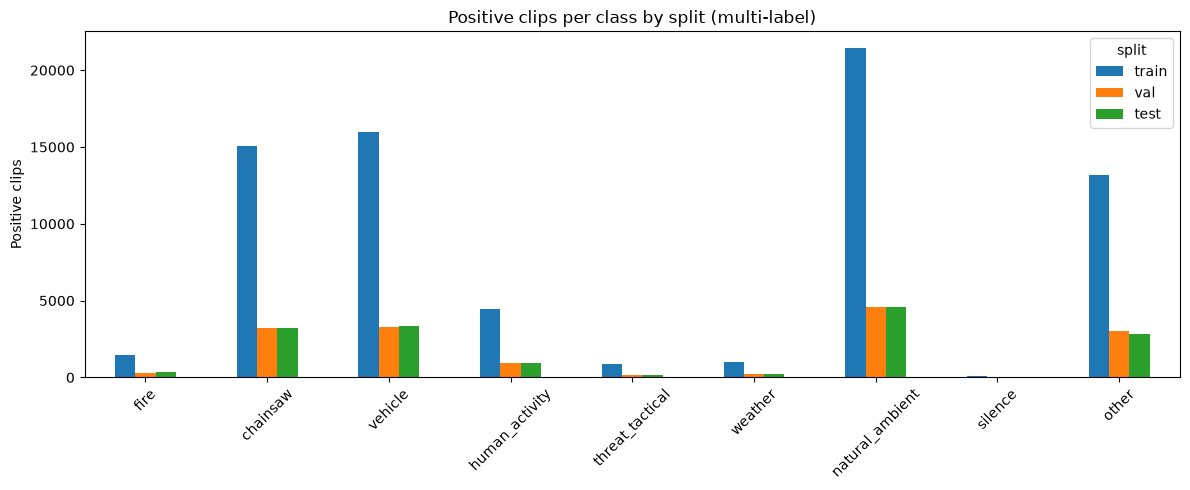

In [11]:
if df[['group_key','split']].isna().any().any(): raise ValueError('group_key/split มีค่าว่าง; ตรวจ manifest จาก 02')
split_groups=df.groupby('group_key').split.nunique()
leaked=split_groups[split_groups>1]
print('Groups crossing splits:',len(leaked))
if len(leaked): raise ValueError('พบ group leakage; กลับไปตรวจ split ใน 02 ก่อน train')
fig,ax=plt.subplots(figsize=(12,5))
support.reindex(['train','val','test']).T.plot(kind='bar',ax=ax)
ax.set_title('Positive clips per class by split (multi-label)'); ax.set_ylabel('Positive clips'); ax.tick_params(axis='x',rotation=45); plt.tight_layout(); plt.show()
class_order=CLASS_ORDER
index_to_class={i:name for i,name in enumerate(class_order)}


## 5. Audio dataset, waveform mixing และ log-Mel features
Feature ของคลิปต้นฉบับ cache เป็น float16. สำหรับตัวอย่างที่สุ่มผสม จะอ่าน waveform สองคลิปจาก train split, ปรับระดับเสียงรองในช่วง -6 ถึง +3 dB เทียบกับเสียงหลัก, รวม waveform แบบไม่ให้ clip แล้วคำนวณ log-Mel ใหม่. `other`/`silence` ไม่ถูกใช้เป็นแหล่งสำหรับ synthetic mix.

In [12]:
def load_wave(path):
    y,sr=sf.read(path,dtype='float32',always_2d=False)
    if y.ndim==2: y=y.mean(axis=1)
    y=np.asarray(y,dtype=np.float32)
    if sr!=SAMPLE_RATE: y=librosa.resample(y,orig_sr=sr,target_sr=SAMPLE_RATE)
    y-=float(y.mean())
    if len(y)<NUM_SAMPLES: y=np.pad(y,(0,NUM_SAMPLES-len(y)))
    elif len(y)>NUM_SAMPLES: y=y[:NUM_SAMPLES]
    return y.astype(np.float32)

def to_logmel(y):
    mel=librosa.feature.melspectrogram(y=y,sr=SAMPLE_RATE,n_fft=N_FFT,hop_length=HOP_LENGTH,n_mels=N_MELS,power=2.0)
    logmel=librosa.power_to_db(mel,ref=np.max)
    return ((logmel-logmel.mean())/(logmel.std()+1e-6)).astype(np.float32)

def feature_cache_path(audio_path):
    path=Path(audio_path); stat=path.stat()
    signature=f'{path.resolve()}|{stat.st_size}|{stat.st_mtime_ns}|{SAMPLE_RATE}|{N_MELS}|{N_FFT}|{HOP_LENGTH}'
    return FEATURE_CACHE_DIR/(hashlib.sha1(signature.encode()).hexdigest()+'.npy')

def spec_augment(x):
    x=x.clone(); _,n_mels,n_frames=x.shape
    if random.random()<.5:
        width=random.randint(1,max(1,n_mels//8)); start=random.randint(0,max(0,n_mels-width)); x[:,start:start+width,:]=0
    if random.random()<.5:
        width=random.randint(1,max(1,n_frames//10)); start=random.randint(0,max(0,n_frames-width)); x[:,:,start:start+width]=0
    return x

def mix_waveforms(primary,secondary):
    rms_a=float(np.sqrt(np.mean(primary**2))); rms_b=float(np.sqrt(np.mean(secondary**2)))
    if rms_a<1e-7 or rms_b<1e-7: return primary
    relative_db=random.uniform(*MIX_SNR_DB_RANGE)
    gain=(rms_a/rms_b)*(10**(relative_db/20))
    mixed=primary+gain*secondary
    peak=float(np.max(np.abs(mixed)))
    if peak>0.99: mixed*=0.99/peak
    return mixed.astype(np.float32)

class ForestAudioDataset(Dataset):
    def __init__(self,frame,training=False):
        self.frame=frame.reset_index(drop=True); self.training=training
        self.label_sets=[set(v) for v in self.frame.target_labels_list]
        self.groups=self.frame.group_key.astype(str).tolist()
        self.label_vectors=np.zeros((len(self.frame),len(class_order)),dtype=np.float32)
        for i,labels in enumerate(self.label_sets):
            for label in labels: self.label_vectors[i,class_to_index[label]]=1.0
        self.mix_pools={label:[i for i,labels in enumerate(self.label_sets) if label in labels and not (labels & EXCLUDED_FROM_SYNTHETIC_MIX)] for label in class_order if label not in EXCLUDED_FROM_SYNTHETIC_MIX}
    def __len__(self): return len(self.frame)
    def _partner(self,index):
        labels=self.label_sets[index]
        if labels & EXCLUDED_FROM_SYNTHETIC_MIX: return None
        choices=[label for label in self.mix_pools if label not in labels and self.mix_pools[label]]
        random.shuffle(choices)
        for label in choices:
            pool=self.mix_pools[label]
            for _ in range(12):
                candidate=random.choice(pool)
                if self.groups[candidate]!=self.groups[index]: return candidate
        return None
    def _cached_logmel(self,path):
        cache=feature_cache_path(path)
        if USE_LOGMEL_CACHE and cache.exists(): return np.load(cache).astype(np.float32)
        result=to_logmel(load_wave(path))
        if USE_LOGMEL_CACHE:
            tmp=cache.with_name(cache.stem+'.tmp.npy'); np.save(tmp,result.astype(np.float16)); tmp.replace(cache)
        return result
    def __getitem__(self,index):
        row=self.frame.iloc[index]
        labels=set(self.label_sets[index])
        if self.training and random.random()<MIX_PROBABILITY:
            partner_index=self._partner(index)
        else: partner_index=None
        if partner_index is not None:
            partner=self.frame.iloc[partner_index]
            wave=mix_waveforms(load_wave(row.processed_file),load_wave(partner.processed_file))
            labels|=self.label_sets[partner_index]
            logmel=to_logmel(wave)
        else:
            logmel=self._cached_logmel(row.processed_file)
        x=torch.from_numpy(logmel).unsqueeze(0)
        if self.training: x=spec_augment(x)
        target=np.zeros(len(class_order),dtype=np.float32)
        for label in labels: target[class_to_index[label]]=1.0
        return x,torch.from_numpy(target)

class_to_index={name:i for i,name in enumerate(class_order)}
train_df=df[df.split.eq('train')].copy().reset_index(drop=True)
val_df=df[df.split.eq('val')].copy().reset_index(drop=True)
train_ds=ForestAudioDataset(train_df,training=True); val_ds=ForestAudioDataset(val_df,training=False)
train_loader=DataLoader(train_ds,batch_size=BATCH_SIZE,shuffle=True,num_workers=NUM_WORKERS,pin_memory=(DEVICE.type=='cuda'))
val_loader=DataLoader(val_ds,batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS,pin_memory=(DEVICE.type=='cuda'))
feature_gib_per_clip=(N_MELS*(NUM_SAMPLES//HOP_LENGTH+1)*np.dtype(np.float16).itemsize)/(1024**3)
print(f'Feature cache estimate: ~{feature_gib_per_clip*len(df):.2f} GiB if all original clips cached.')
print('Waveform mix augmentation:',MIX_PROBABILITY,'| SNR dB:',MIX_SNR_DB_RANGE,'| no synthetic WAV files are saved')
x0,y0=next(iter(train_loader)); print('Feature batch:',tuple(x0.shape),'multi-hot target batch:',tuple(y0.shape))
print('Examples with multiple labels in source manifest:',sum(len(labels)>1 for labels in df.target_labels_list))


Feature cache estimate: ~2.52 GiB if all original clips cached.
Waveform mix augmentation: 0.05 | SNR dB: (-6.0, 3.0) | no synthetic WAV files are saved
Feature batch: (32, 1, 64, 201) multi-hot target batch: (32, 9)
Examples with multiple labels in source manifest: 0


## 6. สร้าง multi-label CNN และ loss

In [13]:
class ConvBlock(nn.Module):
    def __init__(self,in_channels,out_channels):
        super().__init__(); self.block=nn.Sequential(nn.Conv2d(in_channels,out_channels,3,padding=1,bias=False),nn.BatchNorm2d(out_channels),nn.ReLU(inplace=True),nn.MaxPool2d(2))
    def forward(self,x): return self.block(x)

class AudioCNN(nn.Module):
    def __init__(self,num_classes):
        super().__init__(); self.features=nn.Sequential(ConvBlock(1,16),ConvBlock(16,32),ConvBlock(32,64),ConvBlock(64,128),nn.AdaptiveAvgPool2d((1,1))); self.classifier=nn.Sequential(nn.Flatten(),nn.Dropout(.35),nn.Linear(128,num_classes))
    def forward(self,x): return self.classifier(self.features(x))

model=AudioCNN(len(class_order)).to(DEVICE)
train_targets=train_ds.label_vectors
positive=train_targets.sum(axis=0); negative=len(train_targets)-positive
pos_weight=np.clip(negative/np.maximum(positive,1),1.0,10.0)
criterion=nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pos_weight,dtype=torch.float32,device=DEVICE))
optimizer=torch.optim.AdamW(model.parameters(),lr=LEARNING_RATE,weight_decay=WEIGHT_DECAY)
scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode='max',factor=.5,patience=2)
print(model)
print('Positive class counts:',dict(zip(class_order,positive.astype(int))))
print('Capped BCE pos_weight:',dict(zip(class_order,pos_weight.round(3))))


AudioCNN(
  (features): Sequential(
    (0): ConvBlock(
      (block): Sequential(
        (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (1): ConvBlock(
      (block): Sequential(
        (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (2): ConvBlock(
      (block): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=Tru

## 7. ฝึกและเลือก checkpoint จาก validation macro-F1
ใช้ sigmoid scores และ threshold เริ่มต้น 0.5 เพื่อวัด macro-F1 แยกคลาส. Early stopping ใช้ validation เท่านั้น; test set ไม่ถูกใช้เลือกรุ่นหรือปรับ threshold.

In [14]:
def multilabel_metrics(y_true,y_prob,threshold=BASE_THRESHOLD):
    y_pred=(y_prob>=threshold).astype(np.int32)
    return {
        'macro_f1':float(f1_score(y_true,y_pred,average='macro',zero_division=0)),
        'micro_f1':float(f1_score(y_true,y_pred,average='micro',zero_division=0)),
        'exact_match':float(np.mean(np.all(y_true==y_pred,axis=1))),
        'predictions':y_pred,
    }

def run_epoch(loader,training):
    model.train(training); total_loss=0.; ys=[]; ps=[]
    context=torch.enable_grad() if training else torch.no_grad()
    with context:
        for xb,yb in tqdm(loader,leave=False):
            xb=xb.to(DEVICE); yb=yb.to(DEVICE)
            if training: optimizer.zero_grad(set_to_none=True)
            logits=model(xb); loss=criterion(logits,yb)
            if training:
                loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(),5.0); optimizer.step()
            total_loss+=float(loss.item())*len(yb)
            ys.append(yb.detach().cpu().numpy()); ps.append(torch.sigmoid(logits).detach().cpu().numpy())
    y_true=np.concatenate(ys); y_prob=np.concatenate(ps)
    metrics=multilabel_metrics(y_true,y_prob)
    return total_loss/max(len(loader.dataset),1),metrics,y_true,y_prob

checkpoint_path=MODEL_DIR/'rakforest_audio_cnn_multilabel_best.pt'
history=[]; best_f1=-1.; best_epoch=0; epochs_without_improvement=0
for epoch in range(1,EPOCHS+1):
    start=time.time(); train_loss,train_metrics,_,_=run_epoch(train_loader,True); val_loss,val_metrics,y_val,val_prob=run_epoch(val_loader,False); scheduler.step(val_metrics['macro_f1'])
    row={'epoch':epoch,'train_loss':train_loss,'train_macro_f1':train_metrics['macro_f1'],'train_micro_f1':train_metrics['micro_f1'],'train_exact_match':train_metrics['exact_match'],'val_loss':val_loss,'val_macro_f1':val_metrics['macro_f1'],'val_micro_f1':val_metrics['micro_f1'],'val_exact_match':val_metrics['exact_match'],'learning_rate':optimizer.param_groups[0]['lr'],'seconds':time.time()-start}
    history.append(row)
    print(f"Epoch {epoch:02d}/{EPOCHS} | train loss {train_loss:.4f}, macroF1 {train_metrics['macro_f1']:.3f} | val loss {val_loss:.4f}, macroF1 {val_metrics['macro_f1']:.3f}, microF1 {val_metrics['micro_f1']:.3f}, exact {val_metrics['exact_match']:.3f}")
    if val_metrics['macro_f1']>best_f1:
        best_f1=val_metrics['macro_f1']; best_epoch=epoch; epochs_without_improvement=0
        torch.save({'model_type':'multilabel_audio_cnn','schema_version':'multilabel-v1','model_state_dict':model.state_dict(),'class_to_index':class_to_index,'class_names':class_order,'config':{'sample_rate':SAMPLE_RATE,'duration_seconds':DURATION_SECONDS,'n_mels':N_MELS,'n_fft':N_FFT,'hop_length':HOP_LENGTH,'architecture':'AudioCNN-v2-multilabel','output_activation':'sigmoid','decision_threshold':BASE_THRESHOLD,'target_encoding':'multi_hot'},'augmentation':{'type':'waveform_mix','probability':MIX_PROBABILITY,'secondary_snr_db_range':list(MIX_SNR_DB_RANGE),'excluded_tags':sorted(EXCLUDED_FROM_SYNTHETIC_MIX)},'best_epoch':best_epoch,'best_val_macro_f1':best_f1,'manifest_signature':MANIFEST_SIGNATURE,'manifest_datasets':sorted(df.dataset.unique()),'training_datasets':sorted(train_df.dataset.unique())},checkpoint_path)
    else:
        epochs_without_improvement+=1
        if epochs_without_improvement>=PATIENCE: print('Early stopping.'); break

history_df=pd.DataFrame(history); history_df.to_csv(REPORT_DIR/'multilabel_training_history.csv',index=False)
print('Best epoch:',best_epoch,'best validation macro-F1:',round(best_f1,4)); print('Checkpoint:',checkpoint_path)


Epoch 01/20 | train loss 0.3788, macroF1 0.489 | val loss 0.2894, macroF1 0.543, microF1 0.752, exact 0.644


Epoch 02/20 | train loss 0.3057, macroF1 0.548 | val loss 0.3813, macroF1 0.502, microF1 0.703, exact 0.611


Epoch 03/20 | train loss 0.2826, macroF1 0.572 | val loss 0.2025, macroF1 0.606, microF1 0.798, exact 0.685


Epoch 04/20 | train loss 0.2642, macroF1 0.589 | val loss 0.2560, macroF1 0.585, microF1 0.747, exact 0.550


Epoch 05/20 | train loss 0.2519, macroF1 0.599 | val loss 0.1661, macroF1 0.654, microF1 0.840, exact 0.746


Epoch 06/20 | train loss 0.2394, macroF1 0.612 | val loss 0.1756, macroF1 0.638, microF1 0.822, exact 0.729


... (5 outputs left out)

Epoch 12/20 | train loss 0.2003, macroF1 0.663 | val loss 0.1405, macroF1 0.706, microF1 0.864, exact 0.803


Epoch 13/20 | train loss 0.1957, macroF1 0.670 | val loss 0.1559, macroF1 0.663, microF1 0.850, exact 0.787


Epoch 14/20 | train loss 0.1929, macroF1 0.671 | val loss 0.1360, macroF1 0.703, microF1 0.868, exact 0.807


Epoch 15/20 | train loss 0.1826, macroF1 0.688 | val loss 0.1324, macroF1 0.710, microF1 0.870, exact 0.807
Early stopping.
Best epoch: 11 best validation macro-F1: 0.7139
Checkpoint: /Users/guidegiegg/Projects/RakForest-ML/models/rakforest_audio_cnn_multilabel_best.pt


## 8. Training curves และ validation report

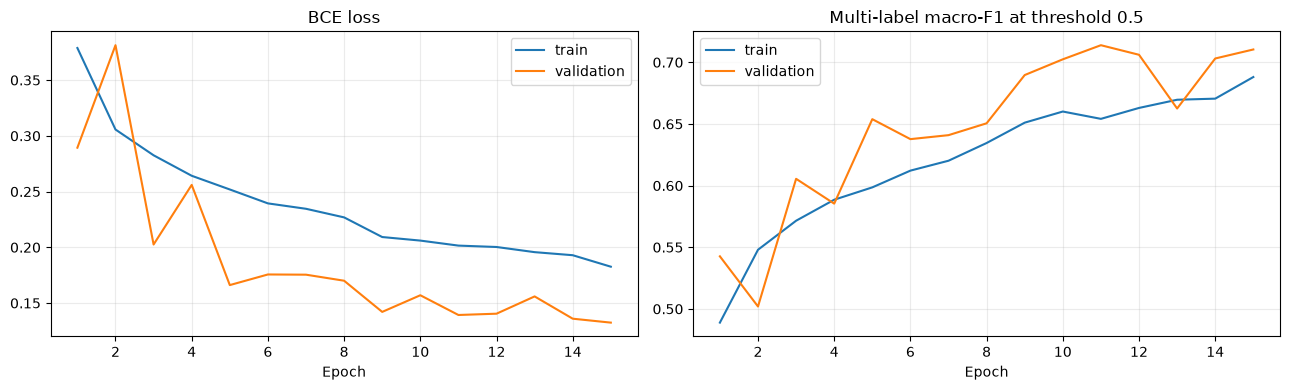

Validation macro-F1: 0.7139 | micro-F1: 0.8659 | exact match: 0.8026
                 precision    recall  f1-score   support

           fire      0.769     0.947     0.849       302
       chainsaw      0.899     0.943     0.921      3219
        vehicle      0.885     0.941     0.912      3259
 human_activity      0.552     0.971     0.704       952
threat_tactical      0.391     0.759     0.516       170
        weather      0.297     0.820     0.436       211
natural_ambient      0.890     0.957     0.922      4605
        silence      0.222     0.636     0.329        22
          other      0.736     0.968     0.836      3028

      micro avg      0.796     0.949     0.866     15768
      macro avg      0.627     0.882     0.714     15768
   weighted avg      0.824     0.949     0.877     15768
    samples avg      0.872     0.949     0.896     15768



In [15]:
fig,axes=plt.subplots(1,2,figsize=(13,4))
axes[0].plot(history_df.epoch,history_df.train_loss,label='train'); axes[0].plot(history_df.epoch,history_df.val_loss,label='validation'); axes[0].set_title('BCE loss'); axes[0].legend()
axes[1].plot(history_df.epoch,history_df.train_macro_f1,label='train'); axes[1].plot(history_df.epoch,history_df.val_macro_f1,label='validation'); axes[1].set_title('Multi-label macro-F1 at threshold 0.5'); axes[1].legend()
for ax in axes: ax.set_xlabel('Epoch'); ax.grid(alpha=.25)
plt.tight_layout(); plt.show()

checkpoint=torch.load(checkpoint_path,map_location=DEVICE,weights_only=True)
model.load_state_dict(checkpoint['model_state_dict']); model.eval()
_,val_metrics,y_val,val_prob=run_epoch(val_loader,False)
y_val_pred=val_metrics['predictions']
print(f"Validation macro-F1: {val_metrics['macro_f1']:.4f} | micro-F1: {val_metrics['micro_f1']:.4f} | exact match: {val_metrics['exact_match']:.4f}")
print(classification_report(y_val,y_val_pred,target_names=class_order,zero_division=0,digits=3))


## 9. บันทึก model card/config สำหรับ evaluation
บันทึก schema/model version, target classes, preprocessing, waveform-mix config, manifest signature และ validation metrics.

In [16]:
model_config={
 'model_name':'RakForest AudioCNN multi-label baseline','model_type':'multilabel_audio_cnn','schema_version':'multilabel-v1',
 'checkpoint':str(checkpoint_path.relative_to(PROJECT_ROOT)),'class_names':class_order,'class_to_index':class_to_index,
 'input':{'sample_rate':SAMPLE_RATE,'duration_seconds':DURATION_SECONDS,'num_samples':NUM_SAMPLES,'channels':1},
 'features':{'type':'log_mel_spectrogram','n_mels':N_MELS,'n_fft':N_FFT,'hop_length':HOP_LENGTH,'per_clip_standardization':True},
 'targets':{'encoding':'multi_hot','activation':'sigmoid','default_threshold':BASE_THRESHOLD,'silence_other_are_mutually_exclusive_tags':True},
 'augmentation':{'type':'waveform_mix','probability':MIX_PROBABILITY,'secondary_snr_db_range':list(MIX_SNR_DB_RANGE),'excluded_tags':sorted(EXCLUDED_FROM_SYNTHETIC_MIX)},
 'training':{'seed':SEED,'batch_size':BATCH_SIZE,'learning_rate':LEARNING_RATE,'weight_decay':WEIGHT_DECAY,'max_epochs':EPOCHS,'early_stopping_patience':PATIENCE,'selection_metric':'validation macro-F1 at 0.5','best_epoch':best_epoch,'best_validation_macro_f1':best_f1},
 'manifest':str(MANIFEST_PATH.relative_to(PROJECT_ROOT)),'manifest_signature':MANIFEST_SIGNATURE,'test_split_used':False}
config_path=MODEL_DIR/'rakforest_audio_cnn_multilabel_config.json'; config_path.write_text(json.dumps(model_config,indent=2,ensure_ascii=False))
validation={'best_epoch':best_epoch,'val_macro_f1':float(val_metrics['macro_f1']),'val_micro_f1':float(val_metrics['micro_f1']),'val_exact_match':float(val_metrics['exact_match']),'train_rows':len(train_df),'val_rows':len(val_df),'test_rows':int(df.split.eq('test').sum()),'class_names':class_order,'threshold':BASE_THRESHOLD,'schema_version':'multilabel-v1'}
metrics_path=REPORT_DIR/'multilabel_validation_metrics.json'; metrics_path.write_text(json.dumps(validation,indent=2,ensure_ascii=False))
print('Saved:',checkpoint_path,config_path,metrics_path)
print('Next: run 04_evaluate_model.ipynb to evaluate held-out test split.')


Saved: /Users/guidegiegg/Projects/RakForest-ML/models/rakforest_audio_cnn_multilabel_best.pt /Users/guidegiegg/Projects/RakForest-ML/models/rakforest_audio_cnn_multilabel_config.json /Users/guidegiegg/Projects/RakForest-ML/reports/multilabel_validation_metrics.json
Next: run 04_evaluate_model.ipynb to evaluate held-out test split.


## Outputs
- `models/rakforest_audio_cnn_multilabel_best.pt` — multi-label weights พร้อม class order, schema version, provenance และ augmentation config
- `models/rakforest_audio_cnn_multilabel_config.json` — preprocessing/model configuration
- `reports/multilabel_training_history.csv` — metrics ต่อ epoch
- `reports/multilabel_validation_metrics.json` — validation metrics ที่ threshold 0.5

Checkpoint เก่าแบบ single-label ใช้กับ 04/05 เวอร์ชัน multi-label ไม่ได้. หากคลาสไม่มีตัวอย่าง positive ใน train จะหยุดก่อนเริ่มฝึก.